# MAXQDA × LDA × GPT: Publication-Ready Triangulation

**Vietnamese depression-related language | Label 1 qualitative sample**

Reproducible notebook preparing **four journal-ready PDF outputs** from the researcher's analysis files:

1. **Thematic-frequency table (15 themes)** — coded segments, coded documents, within-sample percentages, and compact percentage bars.
2. **15 × 7 LDA–MAXQDA correspondence heatmap** — within-topic coded-document percentages.
3. **Three-way joint-display table** — LDA topic, MAXQDA theme, GPT primary annotations, and convergence/divergence interpretation.
4. **Representative Vietnamese quotations with draft English translations** — exact coded passages extracted from the original QDPX (never invented).

**Grounding and scope:** Original purposive sample *n* = 245; 14 uncoded texts excluded from the reviewed coded subset; retained *n* = **231**. Human-developed codebook (15 themes) with **523** code-to-passage links after an AI-assisted first pass and researcher validation as reported by the research team. Of 231 retained texts, **182** have GPT thematic annotations (**210** model/source records); **49** have none. The labels describe language in texts, not diagnoses.

**How to run:** Put this notebook beside the included `data/` folder; choose **Kernel → Restart & Run All**. Requires Python 3.10+, NumPy and Matplotlib. No pandas or Excel library is needed. All generated figures/tables go to `outputs/`.

> **Publication cautions.** Percentages are descriptive overlaps, not independent validation or classifier performance. A document can have multiple MAXQDA themes; GPT counts are records, not necessarily unique texts. The 231-text restriction inflates some overlap rates relative to the original 245-text sample; retain the sensitivity comparison. Draft translations require researcher verification, and identifiable/sensitive content must be screened before publication.


In [1]:
from pathlib import Path
import csv, json, math, re, textwrap, zipfile, collections
from xml.etree import ElementTree as ET
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import patches, colors, font_manager
from IPython.display import display, Markdown

ROOT = Path.cwd()
DATA = ROOT / "data"
OUT = ROOT / "outputs"
OUT.mkdir(exist_ok=True)
for file in ["lda_counts.csv", "lda_rates.csv", "theme_frequencies.csv", "document_linkage.csv", "gpt_annotations.csv", "maxqda_label1_231.qdpx"]:
    assert (DATA / file).exists(), f"Missing: {DATA/file}"

# Consistent journal style; all figure exports are vector PDF only.
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.unicode_minus": False, "pdf.fonttype": 42, "ps.fonttype": 42,
    "savefig.facecolor": "white", "figure.facecolor": "white"
})
NAVY = "#17324A"; TEAL = "#147C83"; MUTED = "#516779"
PAPER = "#FAFCFD"; LINE = "#E2EAF0"; AMBER = "#B27325"

def rows(filename):
    with (DATA / filename).open("r", encoding="utf-8-sig", newline="") as f:
        return list(csv.DictReader(f))

def nint(v): return int(float(v))
def savefig(fig, base):
    """Export one publication-ready vector PDF (no PNG or SVG)."""
    destination = OUT / f"{base}.pdf"
    fig.savefig(destination, format="pdf", bbox_inches="tight",
                facecolor="white", pad_inches=0.18)
    print(f"Saved {destination.name}")

def write_csv(name, header, data):
    with (OUT / name).open("w",encoding="utf-8-sig",newline="") as f:
        w=csv.writer(f); w.writerow(header); w.writerows(data)

print("Input folder:", DATA)


Input folder: c:\Users\it08d\OneDrive - kcg.ac.jp\_KCGI\_Projects\_Done\Depression_Thay Cach\vietnamese-depression-nlp\MAXQDA_Triangulation\data


## 1. Load and verify the study denominators

The **LDA–MAXQDA** matrix is computed at document level: for topic *t*, `100 × (# documents in t receiving code c) / (# retained documents in t)`. Because one document may carry several codes, percentages in a column need not sum to 100%.


In [2]:
freq = rows("theme_frequencies.csv")
counts_csv = rows("lda_counts.csv")
rates_csv = rows("lda_rates.csv")
links = rows("document_linkage.csv")
gpt = rows("gpt_annotations.csv")
keys = [f"T{i}" for i in range(1,8)]
headers = list(counts_csv[0].keys())
topic_columns = headers[1:8]
topic_sizes = np.array([int(re.search(r"n=(\d+)", h).group(1)) for h in topic_columns])
themes = [r["MAXQDA theme"] for r in counts_csv]
count_mat = np.array([[nint(r[h]) for h in topic_columns] for r in counts_csv],dtype=int)
rate_mat = 100.0 * count_mat / topic_sizes[None,:]
assert len(themes) == 15 and len(links) == 231 and len(gpt) == 210
assert int(topic_sizes.sum()) == 231
assert len(set(r["QDA ID"] for r in links)) == 231
assert len(set(r["QDA ID"] for r in gpt)) == 182
assert count_mat.sum() == 523, "Code counts must reconcile with 523 assignments"
assert all(abs(rate_mat[i,j]/100-float(rates_csv[i][list(rates_csv[i].keys())[j+1]])) < 1e-8
           for i in range(15) for j in range(7))
assert sum(nint(r["Coded passages"]) for r in freq) == 523

lda_topic_names = {
    "T1": "Medication & treatment", "T2": "Anxiety & somatic symptoms",
    "T3": "Psychosocial stress", "T4": "Public discourse",
    "T5": "Help-seeking & information", "T6": "Commentary & trivialization",
    "T7": "Severe distress & suicidality"
}
print("Verified: 231 texts; 15 codes; 523 coded segments; topic sizes",dict(zip(keys, topic_sizes)))
print("GPT: 210 annotation records from 182 texts; 49 missing GPT annotations")


Verified: 231 texts; 15 codes; 523 coded segments; topic sizes {'T1': np.int64(30), 'T2': np.int64(35), 'T3': np.int64(44), 'T4': np.int64(10), 'T5': np.int64(36), 'T6': np.int64(29), 'T7': np.int64(47)}
GPT: 210 annotation records from 182 texts; 49 missing GPT annotations


## 2. Figure A — Validated MAXQDA thematic-frequency table

A journal-ready **15-theme frequency table** sorted by coded-segment count. Each row reports **coded passages (n)**, **distinct coded texts (n)**, and the **share of the 231 retained Label 1 texts (%)**. The slim horizontal indicator uses an explicit 0–40% scale. Multiple themes may occur in one text, so percentages must **not** sum to 100%. The 245-to-231 retention decision is disclosed in the footnote. In this dataset, each code has one segment per coded text; future revisions may change that equality.

**Output:** `outputs/figure_maxqda_thematic_frequency_table.pdf` (vector PDF only). The accompanying CSV stores the numeric entries for native LaTeX tabulation if preferred.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


Saved figure_maxqda_thematic_frequency_table.pdf


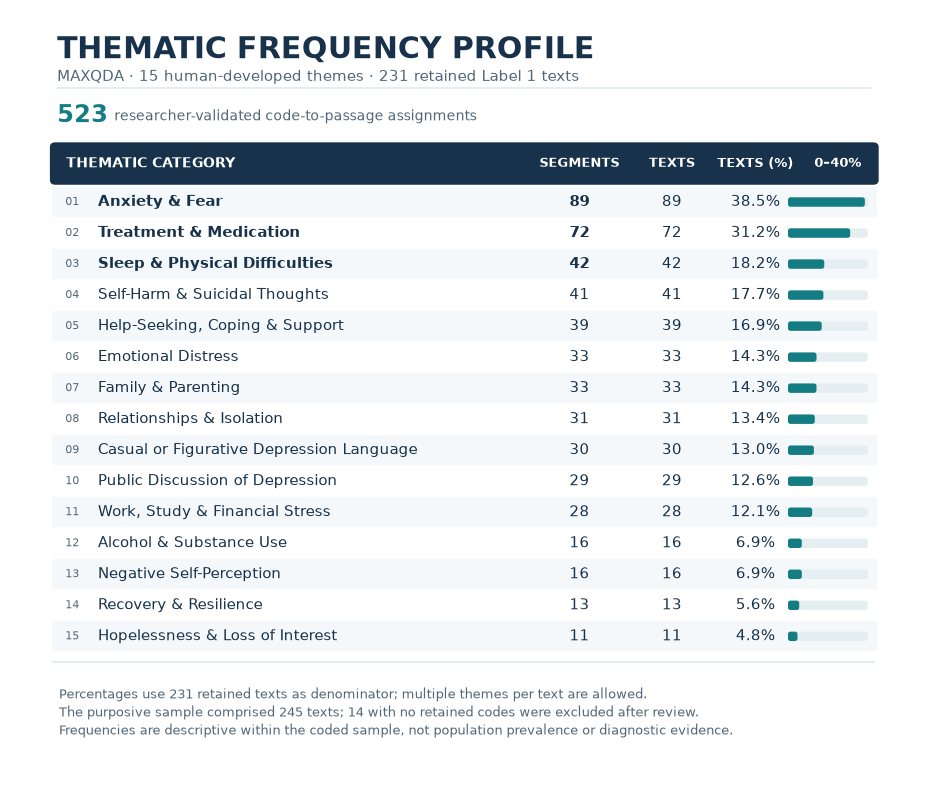

Reconciled: 523 coded segments across 15 themes


In [3]:
# Frequency counts are read from the supplied analysis CSV, never typed into the figure.
from matplotlib.patches import Rectangle, FancyBboxPatch

freq_ordered = sorted(freq, key=lambda r: (-nint(r["Coded passages"]), r["MAXQDA thematic code"]))
assert len(freq_ordered) == 15
freq_data = []
for entry in freq_ordered:
    c = nint(entry["Coded passages"])
    d = nint(entry["Coded documents"])
    pct = 100*d/231
    assert abs(pct/100 - float(entry["Share of retained 231 texts"])) < 1e-10
    freq_data.append((entry["MAXQDA thematic code"], c, d, pct))
assert sum(r[1] for r in freq_data) == 523
assert all(0 <= x[2] <= 231 for x in freq_data)
write_csv("maxqda_theme_frequency_table.csv",
          ["Thematic category", "Coded segments (n)", "Coded documents (n)", "Share of 231 texts (%)"],
          [[label, c, d, f"{p:.1f}"] for label,c,d,p in freq_data])

fig, ax = plt.subplots(figsize=(11.7, 10.2))
fig.patch.set_facecolor("white")
ax.set_xlim(0,1); ax.set_ylim(0,1); ax.axis("off")

# Editorial header and annotation bar.
ax.text(.052,.967,"THEMATIC FREQUENCY PROFILE",fontsize=21.5,color=NAVY,
        weight="bold",va="top",transform=ax.transAxes)
ax.text(.052,.924,"MAXQDA · 15 human-developed themes · 231 retained Label 1 texts",
        fontsize=11,color=MUTED,va="top",transform=ax.transAxes)
ax.plot([.052,.948],[.900,.900],lw=1.2,color=LINE,transform=ax.transAxes)
ax.text(.052,.880,"523",fontsize=17.3,weight="bold",color=TEAL,va="top",transform=ax.transAxes)
ax.text(.115,.873,"researcher-validated code-to-passage assignments",fontsize=10.2,
        color=MUTED,va="top",transform=ax.transAxes)

# Table header (header labels wrap where needed).
header_top=.827; header_h=.051; row_top=header_top-.008
ax.add_patch(FancyBboxPatch((.046,header_top-.048),.910,.050,
             boxstyle="round,pad=0.002,rounding_size=0.006",facecolor=NAVY,
             edgecolor="none",transform=ax.transAxes))
ax.text(.062,header_top-.023,"THEMATIC CATEGORY",fontsize=10.4,fontweight="bold",
        color="white",va="center",transform=ax.transAxes)
for x,s in [(.628,"SEGMENTS"),(.730,"TEXTS"),(.822,"TEXTS (%)")]:
    ax.text(x,header_top-.023,s,fontsize=9.0,fontweight="bold",color="white",
            ha="center",va="center",transform=ax.transAxes)
ax.text(.913,header_top-.023,"0–40%",fontsize=9.0,fontweight="bold",color="white",
        ha="center",va="center",transform=ax.transAxes)

first_y=header_top-.072
rh=.0395
bar_l=.858; bar_w=.088
for i,(label,n_seg,n_doc,pct) in enumerate(freq_data):
    cy=first_y-rh*i
    if i%2==0:
        ax.add_patch(Rectangle((.046,cy-rh*.48),.910,rh*.96,
                    facecolor="#F4F8FA",edgecolor="none",transform=ax.transAxes))
    # ranking small and muted (not part of the theme label)
    ax.text(.061,cy,f"{i+1:02d}",fontsize=8.2,color=MUTED,ha="left",va="center",transform=ax.transAxes)
    ax.text(.097,cy,label,fontsize=10.7,color=NAVY,ha="left",va="center",
            fontweight="semibold" if i < 3 else "normal",transform=ax.transAxes)
    ax.text(.628,cy,f"{n_seg:,}",fontsize=11,color=NAVY,ha="center",va="center",
            fontweight="bold" if i < 3 else "normal",transform=ax.transAxes)
    ax.text(.730,cy,f"{n_doc:,}",fontsize=11,color=NAVY,ha="center",va="center",transform=ax.transAxes)
    ax.text(.822,cy,f"{pct:.1f}%",fontsize=10.7,color=NAVY,ha="center",va="center",transform=ax.transAxes)
    ax.add_patch(FancyBboxPatch((bar_l,cy-.006),bar_w,.012,
                 boxstyle="round,pad=0,rounding_size=0.003",facecolor="#E5EFF1",
                 edgecolor="none",transform=ax.transAxes))
    ax.add_patch(FancyBboxPatch((bar_l,cy-.006),bar_w*min(pct/40.,1.),.012,
                 boxstyle="round,pad=0,rounding_size=0.003",facecolor=TEAL,
                 edgecolor="none",transform=ax.transAxes))

base_y=first_y-rh*(len(freq_data)-1)-.033
ax.plot([.047,.953],[base_y,base_y],color=LINE,lw=1.25,transform=ax.transAxes)
ax.text(.054,base_y-.032,
        "Percentages use 231 retained texts as denominator; multiple themes per text are allowed.",
        fontsize=9.5,color=MUTED,va="top",transform=ax.transAxes)
ax.text(.054,base_y-.055,
        "The purposive sample comprised 245 texts; 14 with no retained codes were excluded after review.",
        fontsize=9.5,color=MUTED,va="top",transform=ax.transAxes)
ax.text(.054,base_y-.078,
        "Frequencies are descriptive within the coded sample, not population prevalence or diagnostic evidence.",
        fontsize=9.4,color=MUTED,va="top",transform=ax.transAxes)

savefig(fig,"figure_maxqda_thematic_frequency_table")
plt.show()
print("Reconciled:", sum(r[1] for r in freq_data), "coded segments across", len(freq_data), "themes")

## 3. Figure B — MAXQDA × LDA thematic heatmap

Shading and values are **within-topic coded-document percentages**, not an overall diagnostic measure. Orange outlined cells denote *analyst-selected conceptually related pairs*; they are interpretive anchors, **not statistical significance or ground truth**.


findfont: Failed to find font weight medium for DejaVu Sans, now using 400.


Saved figure_maxqda_lda_heatmap.pdf


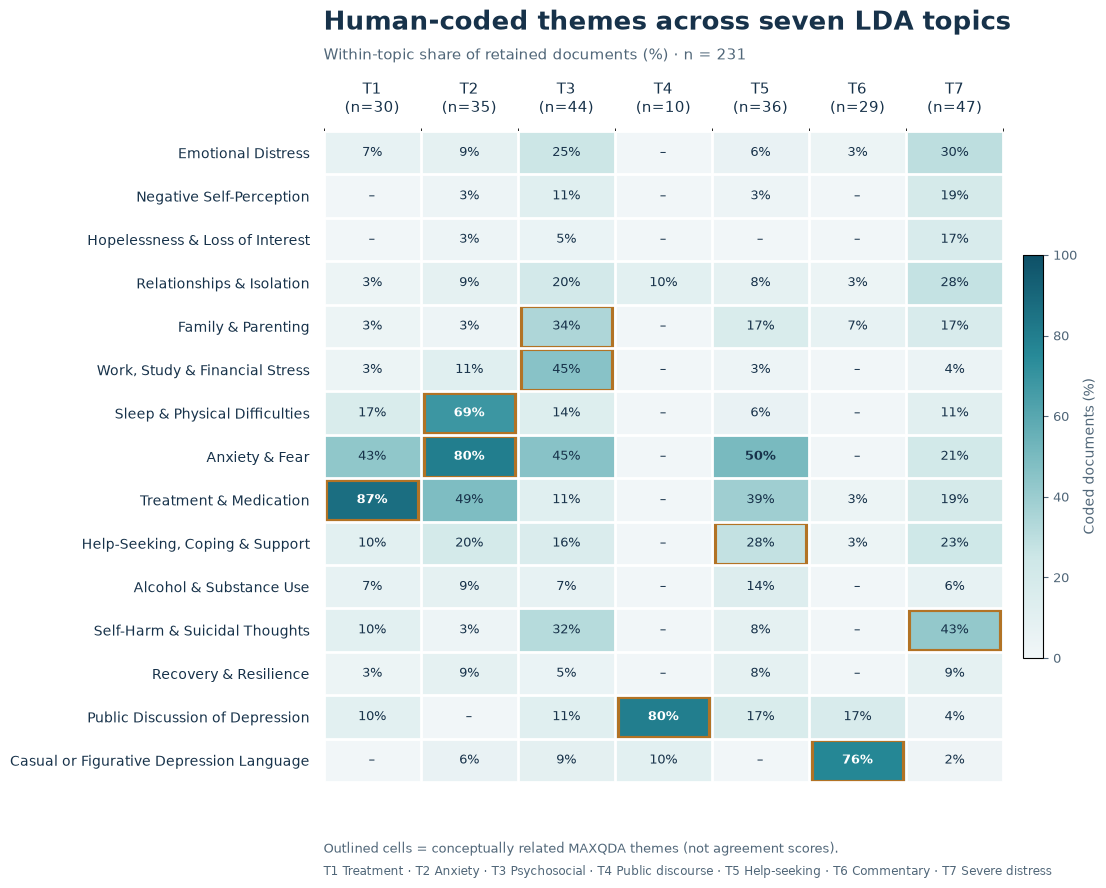

In [4]:
# Edit this mapping only when conceptually justified by the manuscript's thematic definitions.
anchor_pairs = {
    "T1": ["Treatment & Medication"],
    "T2": ["Anxiety & Fear", "Sleep & Physical Difficulties"],
    "T3": ["Work, Study & Financial Stress", "Family & Parenting"],
    "T4": ["Public Discussion of Depression"],
    "T5": ["Help-Seeking, Coping & Support"],
    "T6": ["Casual or Figurative Depression Language"],
    "T7": ["Self-Harm & Suicidal Thoughts"],
}

fig, ax = plt.subplots(figsize=(12.2, 9.3))
fig.patch.set_facecolor("white")
from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list("ocean",["#F1F6F8","#CDE7E7","#7ABBC0","#278A98","#0E5067"])
im=ax.imshow(rate_mat,cmap=cmap,vmin=0,vmax=100,aspect="auto",interpolation="nearest")
ax.set_xticks(range(7),[f"{k}\n(n={topic_sizes[i]})" for i,k in enumerate(keys)],fontsize=11,fontweight="medium",color=NAVY)
ax.set_yticks(range(15),themes,fontsize=10,color=NAVY)
ax.tick_params(length=0,pad=10)
ax.xaxis.tick_top()
for spine in ax.spines.values():spine.set_visible(False)
ax.set_xticks(np.arange(-.5,7,1),minor=True);ax.set_yticks(np.arange(-.5,15,1),minor=True)
ax.grid(which="minor",color="white",linewidth=2);ax.tick_params(which="minor",bottom=False,left=False)
for i, theme in enumerate(themes):
    for j, topic in enumerate(keys):
        value=rate_mat[i,j]; label=f"{value:.0f}%" if value>0 else "–"
        txt_color="white" if value>=58 else NAVY
        ax.text(j,i,label,ha="center",va="center",fontsize=9.0,fontweight="bold" if value>=50 else "regular",color=txt_color)
        if theme in anchor_pairs[topic]:
            ax.add_patch(patches.Rectangle((j-.47,i-.47),.94,.94,fill=False,edgecolor=AMBER,linewidth=2.25))
fig.text(.32,.949,"Human-coded themes across seven LDA topics",color=NAVY,fontsize=19,fontweight="bold")
fig.text(.32,.917,"Within-topic share of retained documents (%) · n = 231",color=MUTED,fontsize=11)
bar=fig.colorbar(im,ax=ax,fraction=.028,pad=.028,shrink=.77)
bar.set_ticks([0,20,40,60,80,100]);bar.set_label("Coded documents (%)",fontsize=10,color=MUTED)
bar.ax.tick_params(labelsize=9,colors=MUTED)
fig.subplots_adjust(left=.32,right=.91,top=.84,bottom=.14)
fig.text(.32,.064,"Outlined cells = conceptually related MAXQDA themes (not agreement scores).",color=MUTED,fontsize=9)
fig.text(.32,.04,"T1 Treatment · T2 Anxiety · T3 Psychosocial · T4 Public discourse · T5 Help-seeking · T6 Commentary · T7 Severe distress",color=MUTED,fontsize=8.4)
savefig(fig,"figure_maxqda_lda_heatmap")
plt.show()
write_csv("lda_within_topic_percentages.csv",["MAXQDA theme"] + keys, [[theme]+[round(x,2) for x in rate_mat[i]] for i,theme in enumerate(themes)])


## 4. Three-way comparison: construct a transparent joint display

The **MAXQDA** value is the proportion of retained documents in that LDA topic with a preselected related code. The **GPT** value is the most frequent GPT primary annotation **among records**, not among independent documents (a text may have two source-specific records). Each row thus summarizes related—but not identical—quantities. Interpretive tags are editable editorial judgments, **not computed agreement coefficients**.


In [5]:
link_index={r["QDA ID"]:r for r in links}
records_by_lda={k:[] for k in keys}
for row in gpt:
    k=link_index[row["QDA ID"]]["Dominant LDA"].replace("LDA ","T")
    records_by_lda[k].append(row)

primary_anchor={
 "T1":"Treatment & Medication", "T2":"Anxiety & Fear",
 "T3":"Work, Study & Financial Stress", "T4":"Public Discussion of Depression",
 "T5":"Help-Seeking, Coping & Support", "T6":"Casual or Figurative Depression Language",
 "T7":"Self-Harm & Suicidal Thoughts"
}
# These short labels interpret *themes*, not human participant diagnoses.
interpretation={
 "T1":("Convergent focus","Treatment dominates both descriptions"),
 "T2":("Complementary","Human anxiety; GPT often emphasizes bodily effects"),
 "T3":("Divergent","Broad psychosocial LDA group; GPT often self-harm"),
 "T4":("Divergent / sparse","Strong human public-discourse match; only five GPT records"),
 "T5":("Complementary","Help-seeking topic also has medication content"),
 "T6":("Divergent","Humans flag figurative talk; GPT favors general affect"),
 "T7":("Partial convergence","Self-harm emerges, but LDA topic is broader")
}
rows_joint=[]
for j,k in enumerate(keys):
    anchor=primary_anchor[k]; i=themes.index(anchor)
    c=int(count_mat[i,j]); n=int(topic_sizes[j]); ar=records_by_lda[k]
    cc=collections.Counter(r["GPT primary theme"] for r in ar)
    if cc: gpt_label,gpt_count=cc.most_common(1)[0]
    else:gpt_label,gpt_count="No GPT annotation",0
    tag,reading=interpretation[k]
    rows_joint.append({"lda_topic":k,"lda_name":lda_topic_names[k],"lda_n":n,
        "maxqda_anchor":anchor,"maxqda_documents":c,"maxqda_percent":100*c/n,
        "gpt_most_common":gpt_label,"gpt_records":gpt_count,"gpt_topic_records":len(ar),
        "gpt_unique_texts":len(set(r["QDA ID"] for r in ar)),
        "reading":tag,"comment":reading})

write_csv("three_way_joint_display.csv",list(rows_joint[0]),[[r[k] for k in rows_joint[0]] for r in rows_joint])
for r in rows_joint:
    print(f"{r['lda_topic']}  MAXQDA {r['maxqda_documents']}/{r['lda_n']} ({r['maxqda_percent']:.1f}%) | GPT {r['gpt_records']}/{r['gpt_topic_records']} records | {r['reading']}")


T1  MAXQDA 26/30 (86.7%) | GPT 9/13 records | Convergent focus
T2  MAXQDA 28/35 (80.0%) | GPT 17/35 records | Complementary
T3  MAXQDA 20/44 (45.5%) | GPT 12/50 records | Divergent
T4  MAXQDA 8/10 (80.0%) | GPT 2/5 records | Divergent / sparse
T5  MAXQDA 10/36 (27.8%) | GPT 14/37 records | Complementary
T6  MAXQDA 22/29 (75.9%) | GPT 5/18 records | Divergent
T7  MAXQDA 20/47 (42.6%) | GPT 25/52 records | Partial convergence


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.
findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


Saved figure_three_way_joint_display.pdf


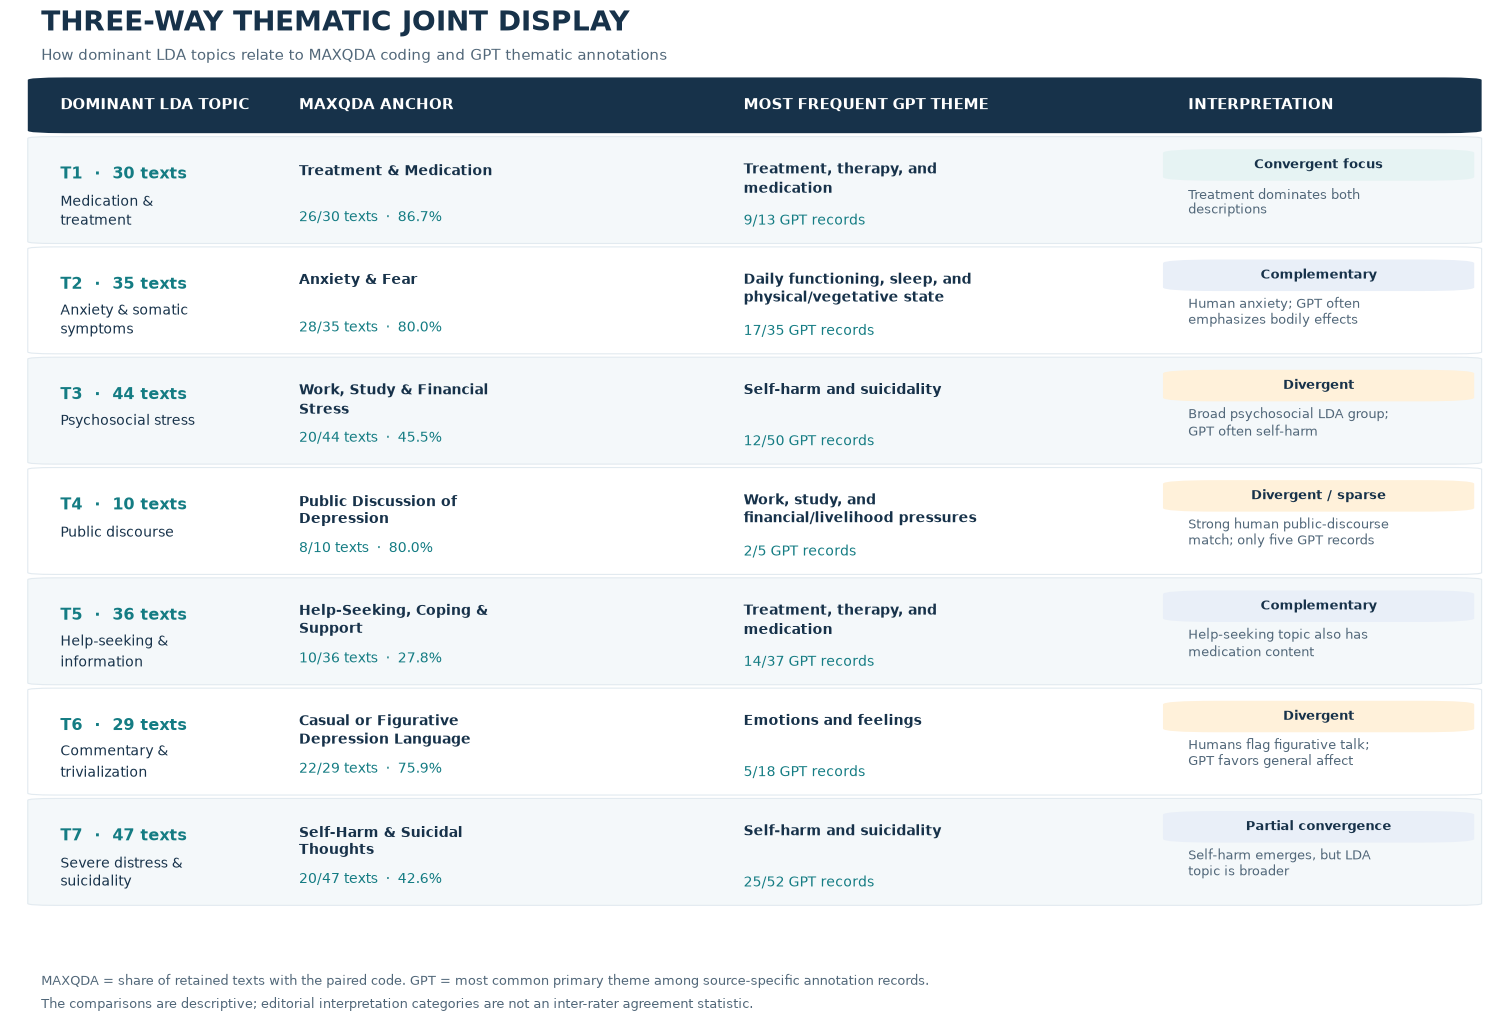

In [6]:
def wrap(s, width):
    return textwrap.fill(str(s),width=width,break_long_words=False,break_on_hyphens=False)

fig, ax=plt.subplots(figsize=(15.6,10.5)); ax.set_xlim(0,1);ax.set_ylim(0,8.9);ax.axis('off')
fig.patch.set_facecolor("white")
fig.text(.05,.955,"THREE-WAY THEMATIC JOINT DISPLAY",fontsize=20,fontweight='bold',color=NAVY)
fig.text(.05,.927,"How dominant LDA topics relate to MAXQDA coding and GPT thematic annotations",fontsize=11,color=MUTED)
cols=[.025,.185,.485,.785,.985]
header_y=8.25
ax.add_patch(patches.FancyBboxPatch((.02,header_y),.965,.54,boxstyle="round,pad=.008,rounding_size=.025",facecolor=NAVY,edgecolor='none'))
for pos,txt in zip([.034,.195,.495,.795],["DOMINANT LDA TOPIC", "MAXQDA ANCHOR", "MOST FREQUENT GPT THEME", "INTERPRETATION"]):
    ax.text(pos,header_y+.27,txt,color="white",fontsize=10.6,va='center',fontweight='bold')

for idx,r in enumerate(rows_joint):
    y=header_y-(idx+1)*1.10
    color="#F4F8FA" if idx%2==0 else "#FFFFFF"
    ax.add_patch(patches.FancyBboxPatch((.02,y),.965,1.05,boxstyle="round,pad=.008,rounding_size=.018",facecolor=color,edgecolor=LINE,linewidth=.8))
    ax.text(.034,y+.76,f"{r['lda_topic']}  ·  {r['lda_n']} texts",color=TEAL,fontweight='bold',fontsize=11.3,va='top')
    ax.text(.034,y+.52,wrap(r['lda_name'],19),color=NAVY,fontsize=10,va='top',linespacing=1.4)
    ax.text(.195,y+.82,wrap(r['maxqda_anchor'],28),color=NAVY,fontsize=10.2,fontweight='semibold',va='top',linespacing=1.3)
    ax.text(.195,y+.32,f"{r['maxqda_documents']}/{r['lda_n']} texts  ·  {r['maxqda_percent']:.1f}%",color=TEAL,fontsize=10,va='top')
    ax.text(.495,y+.82,wrap(r['gpt_most_common'],31),color=NAVY,fontsize=9.9,fontweight='semibold',va='top',linespacing=1.3)
    ax.text(.495,y+.29,f"{r['gpt_records']}/{r['gpt_topic_records']} GPT records",color=TEAL,fontsize=10,va='top')
    badge="#E6F3F3" if "Convergent" in r['reading'] else ("#FFF1DA" if "Divergent" in r['reading'] else "#E9EFF8")
    ax.add_patch(patches.FancyBboxPatch((.790,y+.63),.186,.29,boxstyle="round,pad=.012,rounding_size=.036",facecolor=badge,edgecolor='none'))
    ax.text(.883,y+.777,wrap(r['reading'],21),ha='center',va='center',fontsize=9.1,fontweight='bold',color=NAVY)
    ax.text(.795,y+.57,wrap(r['comment'],29),va='top',fontsize=9.2,color=MUTED,linespacing=1.25)

fig.text(.05,.046,"MAXQDA = share of retained texts with the paired code. GPT = most common primary theme among source-specific annotation records.",fontsize=9,color=MUTED)
fig.text(.05,.024,"The comparisons are descriptive; editorial interpretation categories are not an inter-rater agreement statistic.",fontsize=9,color=MUTED)
fig.subplots_adjust(left=.03,right=.98,top=.92,bottom=.07)
savefig(fig,"figure_three_way_joint_display")
plt.show()


## 5. Recover authentic passages from the original MAXQDA exchange project

For quotation authenticity, **nothing is generated from a topic name**. Each excerpt is selected by its document ID and exact code from the original QDPX, then retrieved directly from its coded text span. The editable English translations below are researcher-review drafts, not validated translations.

**Ethics note:** Descriptions of suicidal thoughts are included only as necessary to illustrate a theme, without method details; protect anonymity and obtain appropriate permissions/ethical clearance before reproducing user-generated content in a publication.


In [7]:
qpath=DATA/"maxqda_label1_231.qdpx"
NS={"q":"urn:QDA-XML:project:1.0"}
with zipfile.ZipFile(qpath,"r") as z:
    project=ET.fromstring(z.read("project.qde"))
    code_lookup={c.attrib["guid"]:c.attrib["name"] for c in project.findall(".//q:CodeBook/q:Codes/q:Code",NS)}
    coded_spans=[]
    doc_text={}
    for src in project.findall(".//q:Sources/q:TextSource",NS):
        qid=src.attrib["name"]
        fname=src.attrib["plainTextPath"].split("internal://",1)[1]
        raw=z.read("sources/"+fname).decode("utf-8-sig")
        doc_text[qid]=raw
        for sel in src.findall("q:PlainTextSelection",NS):
            start,end=int(sel.attrib["startPosition"]),int(sel.attrib["endPosition"])
            assert 0<=start<end<=len(raw), (qid,start,end)
            for c in sel.findall("q:Coding",NS):
                ref=c.find("q:CodeRef",NS).attrib["targetGUID"]
                coded_spans.append({"document":qid,"code":code_lookup[ref],"start":start,"end":end,"vi":raw[start:end]})
assert len(doc_text)==231 and len(coded_spans)==523
print("Authenticity check: 231 embedded documents and 523 valid code-to-text spans")

# Modify only the draft translations or selection IDs, never the Vietnamese excerpts.
QUOTATION_SELECTIONS = [
 {"topic":"T1","document":"QDA-006","code":"Treatment & Medication",
  "en_draft":"Yesterday I had to see the doctor again. My prescription was renewed until the end of April, and I need to see a psychologist to talk about my depression."},
 {"topic":"T2","document":"QDA-066","code":"Anxiety & Fear",
  "en_draft":"But the worst part is the anxiety every day, at least twice a day: my mind panics, I cannot sleep well, and my heart races..."},
 {"topic":"T3","document":"QDA-115","code":"Work, Study & Financial Stress",
  "en_draft":"I work long hours every day as a server because my family is facing serious financial difficulties."},
 {"topic":"T4","document":"QDA-121","code":"Public Discussion of Depression",
  "en_draft":"The France and Manchester United midfielder discussed the mental health of professional footballers following recent comments by Thierry Henry."},
 {"topic":"T5","document":"QDA-164","code":"Help-Seeking, Coping & Support",
  "en_draft":"I want to create a subreddit, a safe place to share experiences and seek or receive advice about men's mental health."},
 {"topic":"T6","document":"QDA-192","code":"Casual or Figurative Depression Language",
  "en_draft":"A quick look at what makes them depressed, and you will realize these are trivial things not worth worrying about."},
 {"topic":"T7","document":"QDA-215","code":"Self-Harm & Suicidal Thoughts",
  "en_draft":"Today, I finally found the courage to tell my mother about my suicidal thoughts, but her reaction left me feeling completely shattered."}
]

quotations=[]
for sel in QUOTATION_SELECTIONS:
    matches=[s for s in coded_spans if s["document"]==sel["document"] and s["code"]==sel["code"]]
    assert len(matches)==1, f"Ambiguous or absent exact selection: {sel}"
    m=matches[0]
    assert m["vi"]==doc_text[m["document"]][m["start"]:m["end"]]
    quotations.append({**sel,"vi_exact":m["vi"],"start":m["start"],"end":m["end"],"translation_status":"DRAFT — researcher verification required"})

write_csv("representative_quotations_REVIEW_BEFORE_PUBLICATION.csv",
 ["topic","document","code","vi_exact","en_draft","start","end","translation_status"],
 [[q[k] for k in ["topic","document","code","vi_exact","en_draft","start","end","translation_status"]] for q in quotations])
print("Selected authentic passages:")
for q in quotations: print(q["topic"],q["document"],"•",q["vi_exact"][:85])


Authenticity check: 231 embedded documents and 523 valid code-to-text spans
Selected authentic passages:
T1 QDA-006 • Hôm qua tôi lại phải đến bác sĩ, đơn thuốc của tôi được gia hạn đến cuối tháng Tư và 
T2 QDA-066 • Nhưng phần tồi tệ nhất là lo âu mỗi ngày, ít nhất hai lần, tâm trí tôi hoảng loạn, kh
T3 QDA-115 • Tôi làm việc nhiều giờ mỗi ngày làm phục vụ vì gia đình tôi rất khó khăn về tài chính
T4 QDA-121 • Tiền vệ của đội tuyển Pháp và Manchester United đã chia sẻ về sức khỏe tinh thần của 
T5 QDA-164 • Tôi muốn tạo ra một subreddit nào đó, một nơi an toàn để chia sẻ, nhận và tìm kiếm lờ
T6 QDA-192 • Một cái nhìn thoáng qua về những gì khiến họ trầm cảm, và bạn sẽ nhận ra đó là những 
T7 QDA-215 • Hôm nay, tôi đã đủ can đảm để chia sẻ suy nghĩ tự sát của mình với mẹ, nhưng phản ứng


## 6. Figure D — Bilingual representative-quotation table

Editable, provenance-checked bilingual excerpts; export as **vector PDF only**. The caption explicitly flags translations as drafts. For the manuscript, keep a compact selection and move the complete table into supplementary material if needed.


Saved figure_bilingual_representative_quotations.pdf


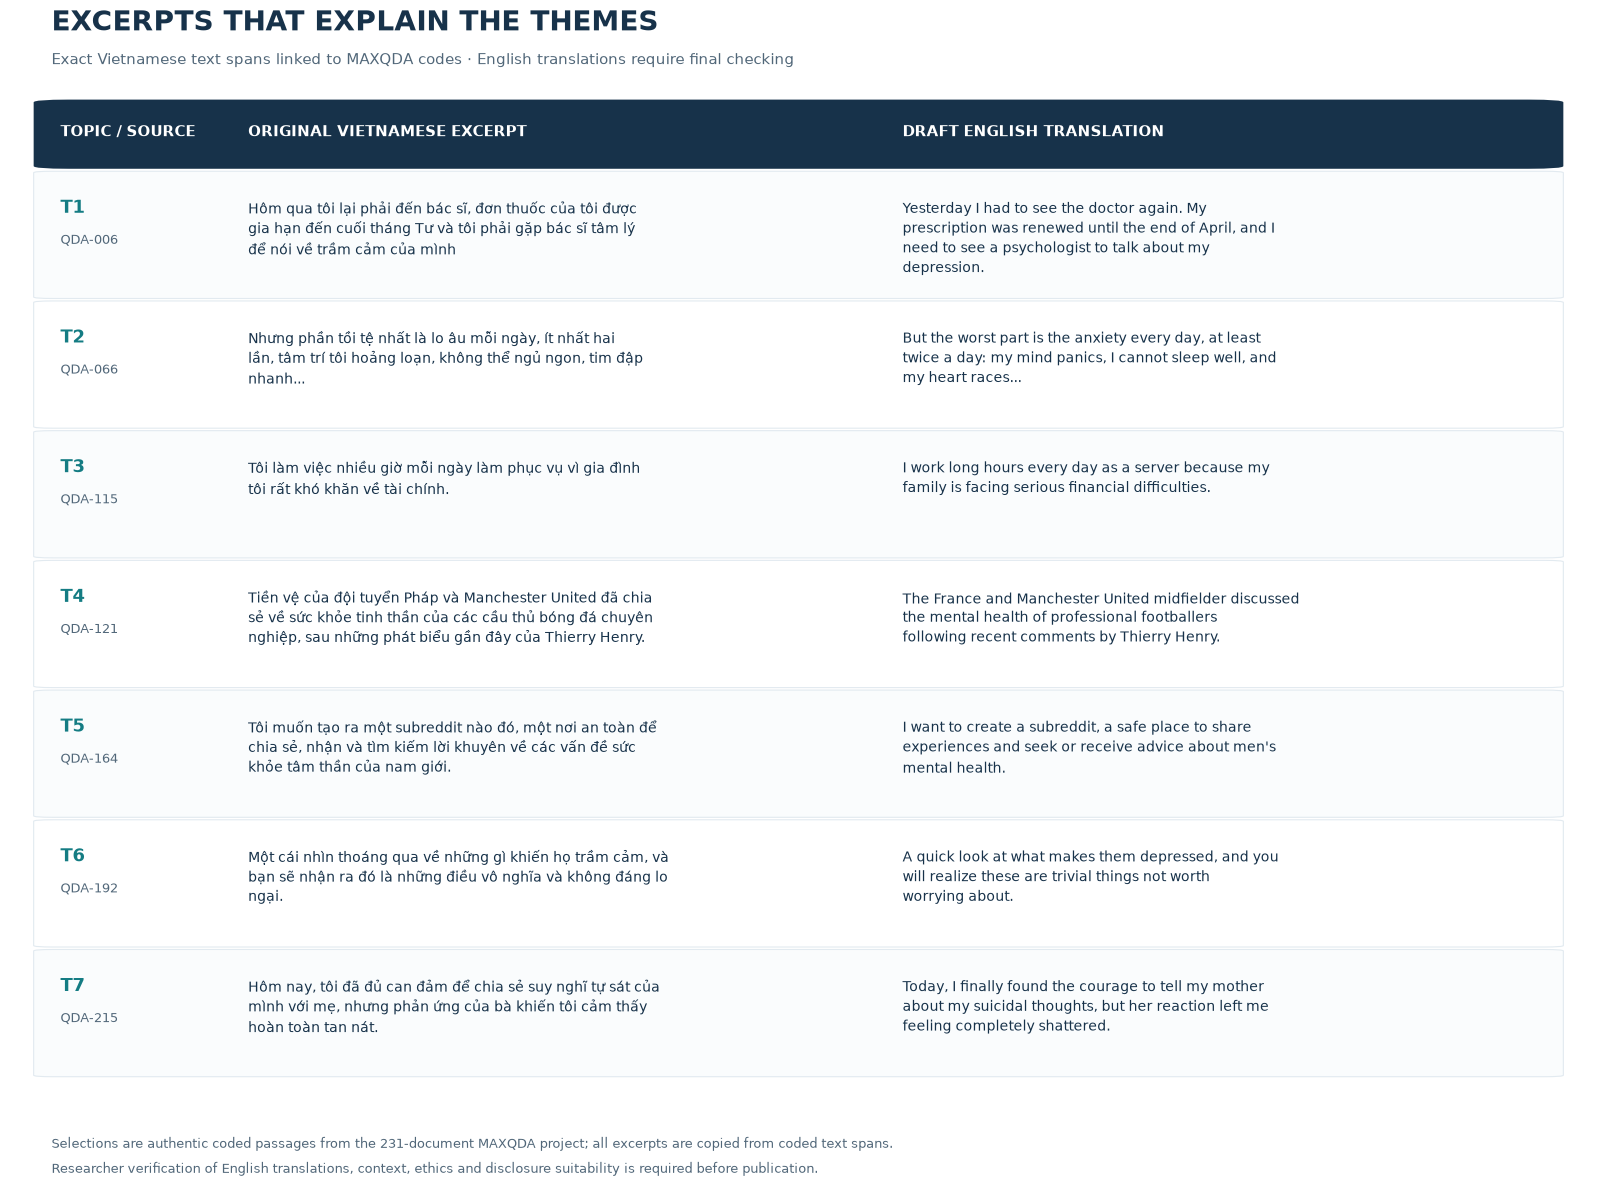

In [8]:
fig,ax=plt.subplots(figsize=(16.6,12.5));fig.patch.set_facecolor("white")
ax.set_xlim(0,1);ax.set_ylim(0,8.5);ax.axis('off')
fig.text(.055,.956,"EXCERPTS THAT EXPLAIN THE THEMES",fontsize=20,color=NAVY,fontweight='bold')
fig.text(.055,.929,"Exact Vietnamese text spans linked to MAXQDA codes · English translations require final checking",fontsize=11,color=MUTED)
col=[.018,.14,.555,.984]
head_y=7.85
ax.add_patch(patches.FancyBboxPatch((.02,head_y),.96,.55,boxstyle="round,pad=.005,rounding_size=.022",facecolor=NAVY,edgecolor='none'))
for xx,title in [(.032,"TOPIC / SOURCE"),(.151,"ORIGINAL VIETNAMESE EXCERPT"),(.566,"DRAFT ENGLISH TRANSLATION")]:
 ax.text(xx,head_y+.29,title,va='center',fontsize=10.6,fontweight='bold',color='white')
for i,q in enumerate(quotations):
 y=head_y-(i+1)*1.05
 ax.add_patch(patches.FancyBboxPatch((.02,y),.96,1.02,boxstyle="round,pad=.005,rounding_size=.012",facecolor=PAPER if i%2==0 else "white",edgecolor=LINE,linewidth=.8))
 ax.text(.032,y+.8,q["topic"],va='top',fontsize=13,color=TEAL,fontweight='bold')
 ax.text(.032,y+.52,q["document"],va='top',fontsize=9.7,color=MUTED)
 ax.text(.151,y+.8,wrap(q["vi_exact"],57),va='top',fontsize=10.0,color=NAVY,linespacing=1.42)
 ax.text(.566,y+.8,wrap(q["en_draft"],54),va='top',fontsize=10.0,color=NAVY,linespacing=1.42)
fig.text(.055,.062,"Selections are authentic coded passages from the 231-document MAXQDA project; all excerpts are copied from coded text spans.",color=MUTED,fontsize=9.4)
fig.text(.055,.042,"Researcher verification of English translations, context, ethics and disclosure suitability is required before publication.",color=MUTED,fontsize=9.4)
fig.subplots_adjust(left=.03,right=.98,top=.91,bottom=.07)
savefig(fig,"figure_bilingual_representative_quotations")
plt.show()


## 7. Optional: quantify one-to-one versus multiple-theme overlap, and report 245-sample sensitivity

These outputs are **supplementary descriptive checks**. They prevent the common error of treating GPT annotation rows as independent people or of presenting selective coded-subset percentages without the original purposive-sample denominator.


In [9]:
# LDA sensitivity percentages already audited in the source workbook.
key_lda=rows("lda_key_comparisons.csv")
print("Original (245) versus retained (231) denominators for selected corresponding codes:")
for r in key_lda:
    if r["LDA topic"] in {"LDA 1","LDA 2","LDA 7"} and r["Related MAXQDA theme"] in {"Treatment & Medication","Anxiety & Fear","Self-Harm & Suicidal Thoughts"}:
        print(r["LDA topic"],r["Related MAXQDA theme"],
            f"original: {float(r['Overlap / original 245 subset']):.1%}",
            f"retained: {float(r['Overlap / 231 subset']):.1%}")

# GPT is record-level. Summarize coverage without treating 210 records as 210 separate texts.
bydoc=collections.Counter(r["QDA ID"] for r in gpt)
assert sum(1 for x in bydoc.values() if x==1)==154
assert sum(1 for x in bydoc.values() if x==2)==28
print("GPT coverage: 154 texts with 1 record; 28 with 2; 49 without a record")


Original (245) versus retained (231) denominators for selected corresponding codes:
LDA 1 Treatment & Medication original: 83.9% retained: 86.7%
LDA 2 Anxiety & Fear original: 70.0% retained: 80.0%
LDA 7 Self-Harm & Suicidal Thoughts original: 40.8% retained: 42.6%
GPT coverage: 154 texts with 1 record; 28 with 2; 49 without a record


## 8. Publication checklist / use in the manuscript

- **Figure A (new):** cite `figure_maxqda_thematic_frequency_table.pdf` or use `maxqda_theme_frequency_table.csv` for a native LaTeX table.
- **Figure C:** cite `figure_maxqda_lda_heatmap.pdf`; interpret outlined anchors as conceptual links, not formal accuracy or agreement.
- **Figure C:** cite `figure_three_way_joint_display.pdf` or use `three_way_joint_display.csv` to build a native LaTeX table. Note that GPT values are **annotation-record counts**.
- **Figure D / Table:** cite `figure_bilingual_representative_quotations.pdf` only after verifying translations, excerpt context, and permissions/ethics. The machine-readable source is `representative_quotations_REVIEW_BEFORE_PUBLICATION.csv`.
- **Reproducibility:** export full provenance and denominators, including the **14 uncoded exclusions** from the 245-text sample, and describe the human-codebook/AI-assisted-placement/researcher-validation sequence accurately.
- **Avoid overclaiming:** overlap does not prove independent human confirmation or clinical validity. Do not equate semantic similarity with item-level Cohen's κ.

**Figure caption suggestion:** “Document-level correspondence between 15 researcher-validated MAXQDA thematic categories and seven dominant LDA topics within 231 retained Vietnamese reference-positive texts. Values represent the percentage of texts assigned the indicated MAXQDA code within each LDA topic. Orange outlines indicate analyst-selected conceptual relationships. Codes may co-occur and comparisons are descriptive.”


**Export policy:** only four `figure_*.pdf` files are generated. Numeric and quotation CSV files remain available for LaTeX or checking; PNG and SVG are not generated.
